Import the library and dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load file
df = pd.read_excel("WHR26_Data_Figure_2.1.xlsx")

# Focus on latest year
df_2025 = df[df["Year"] == 2025].copy()

df.head()

,Year,Rank,Country name,Life evaluation (3-year average),Lower whisker,Upper whisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,2025,1,Finland,7.764,7.690,7.837,1.915,1.638,0.939,1.105,0.093,0.491,1.582
1,2025,2,Iceland,7.540,7.449,7.630,1.971,1.720,0.996,1.105,0.187,0.187,1.373
2,2025,3,Denmark,7.539,7.446,7.631,1.986,1.633,0.930,1.081,0.125,0.474,1.310
3,2025,4,Costa Rica,7.439,7.356,7.522,1.697,1.483,0.739,1.101,0.059,0.122,2.236
4,2025,5,Sweden,7.255,7.172,7.337,1.950,1.570,1.027,1.070,0.149,0.447,1.041


Create the scatter plot with bubble encodings

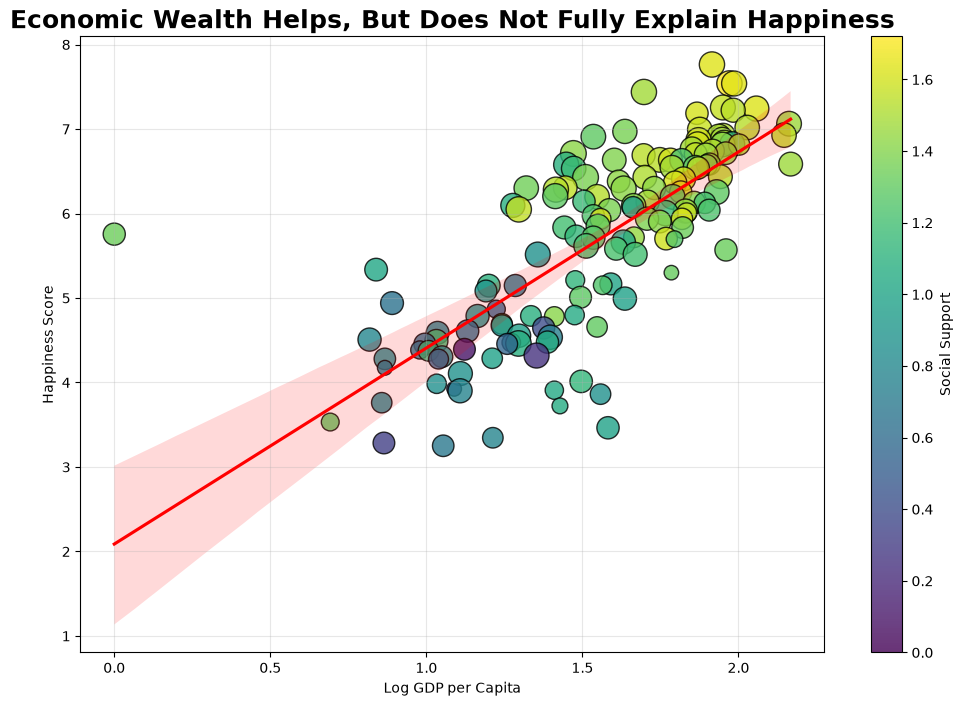

In [2]:
plt.figure(figsize=(12,8))

scatter = plt.scatter(
    df_2025["Explained by: Log GDP per capita"],
    df_2025["Life evaluation (3-year average)"],
    c=df_2025["Explained by: Social support"],
    s=df_2025["Explained by: Freedom to make life choices"]*300,
    cmap="viridis",
    alpha=0.8,
    edgecolors="black"
)

sns.regplot(
    data=df_2025,
    x="Explained by: Log GDP per capita",
    y="Life evaluation (3-year average)",
    scatter=False,
    color="red"
)

plt.colorbar(scatter,label="Social Support")

plt.title(
    "Economic Wealth Helps, But Does Not Fully Explain Happiness",
    fontsize=18,
    weight="bold"
)

plt.xlabel("Log GDP per Capita")
plt.ylabel("Happiness Score")

plt.grid(alpha=0.3)

plt.show()

Build the linear regression and conduct the residual analysis

In [3]:
from sklearn.linear_model import LinearRegression

X = df_2025[["Explained by: Log GDP per capita"]]
y = df_2025["Life evaluation (3-year average)"]

model = LinearRegression()
model.fit(X, y)

df_2025["Predicted_Happiness"] = model.predict(X)

df_2025["Residual"] = (
    df_2025["Life evaluation (3-year average)"]
    - df_2025["Predicted_Happiness"]
)

C:\Users\mario\AppData\Local\Temp\ipykernel_20728\926135265.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


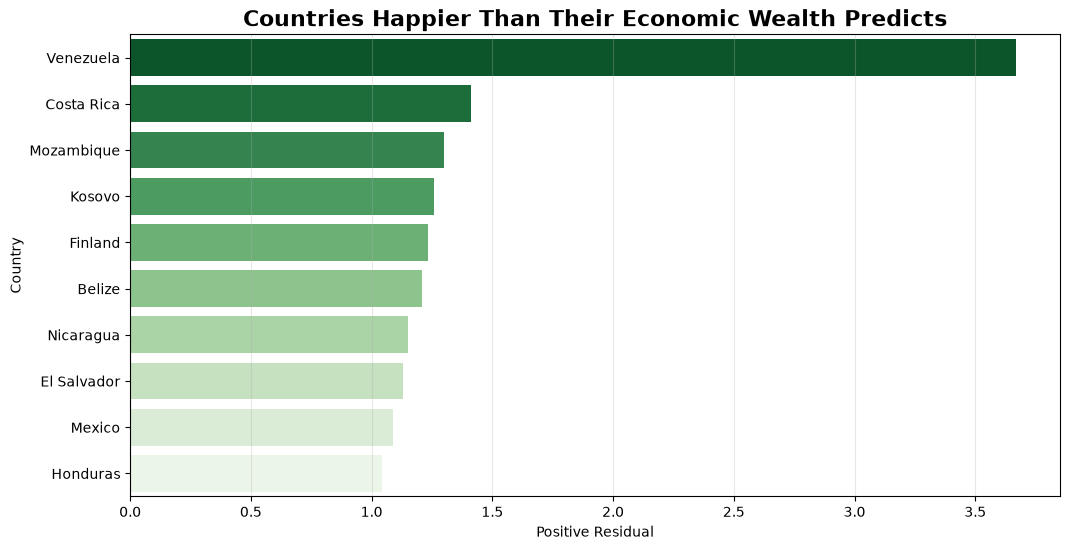

In [4]:
top_positive = df_2025.nlargest(10, "Residual")

plt.figure(figsize=(12,6))

sns.barplot(
    data=top_positive,
    x="Residual",
    y="Country name",
    palette="Greens_r"
)

plt.title(
    "Countries Happier Than Their Economic Wealth Predicts",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Positive Residual")
plt.ylabel("Country")

plt.grid(axis="x", alpha=0.3)

plt.show()

Sort the wealthiest countries and perform comparisons. 

C:\Users\mario\AppData\Local\Temp\ipykernel_20728\4002240651.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


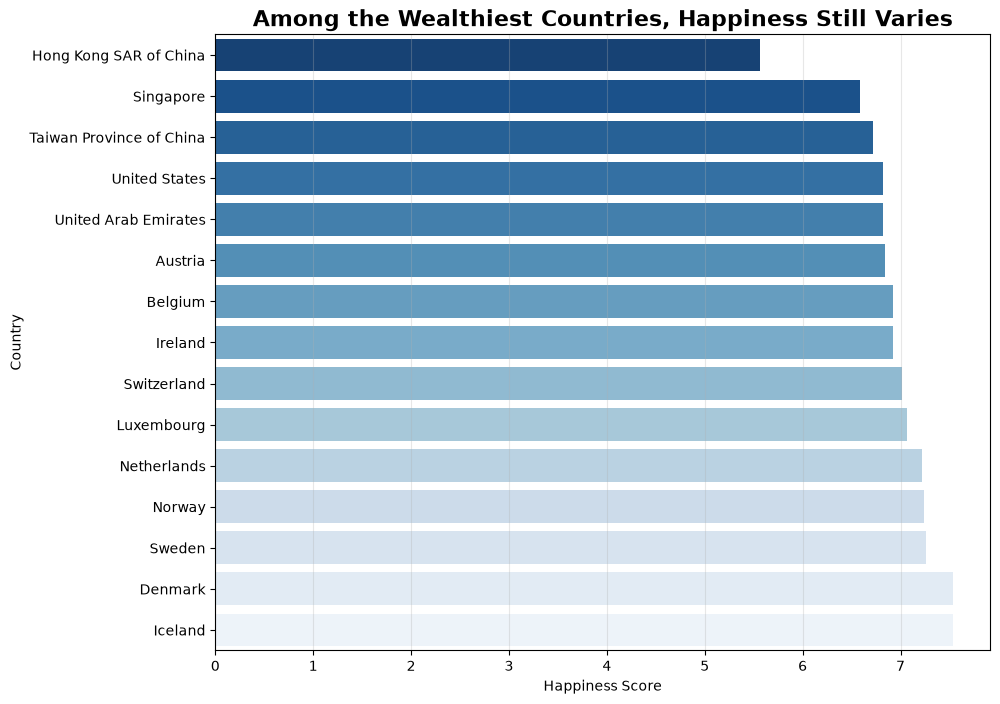

In [5]:
wealthy = df_2025.nlargest(
    15,
    "Explained by: Log GDP per capita"
)

wealthy = wealthy.sort_values(
    "Life evaluation (3-year average)"
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=wealthy,
    x="Life evaluation (3-year average)",
    y="Country name",
    palette="Blues_r"
)

plt.title(
    "Among the Wealthiest Countries, Happiness Still Varies",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Happiness Score")
plt.ylabel("Country")

plt.grid(axis="x", alpha=0.3)

plt.show()

Create the heatmap with different happiness drivers

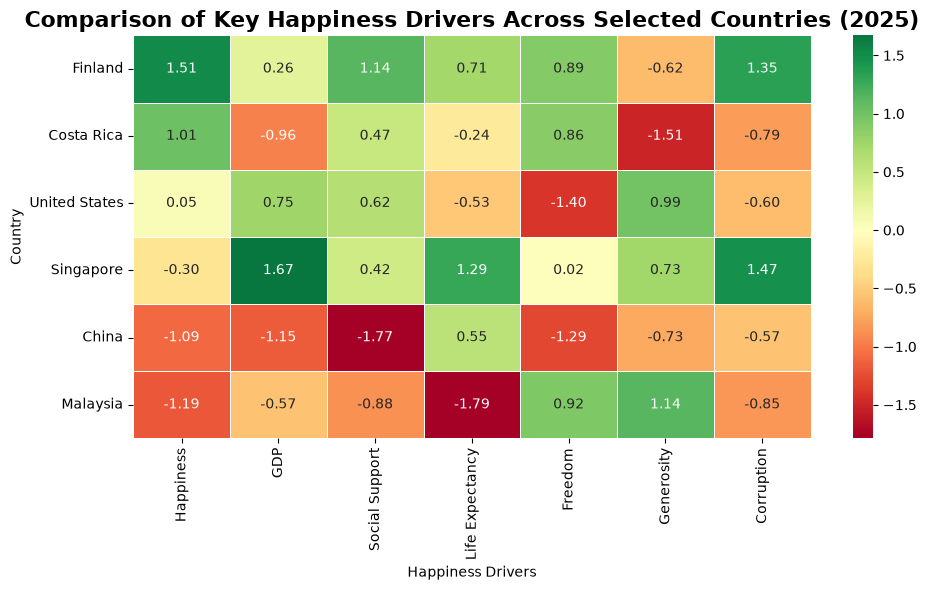

In [8]:
countries = [
    "Finland",
    "Singapore",
    "Costa Rica",
    "United States",
    "Malaysia",
    "China"
]

factors = [
    "Life evaluation (3-year average)",
    "Explained by: Log GDP per capita",
    "Explained by: Social support",
    "Explained by: Healthy life expectancy",
    "Explained by: Freedom to make life choices",
    "Explained by: Generosity",
    "Explained by: Perceptions of corruption"
]

heatmap_data = (
df_2025[df_2025["Country name"].isin(countries)]
.set_index("Country name")[factors]
)

heatmap_data.columns = [
    "Happiness",
    "GDP",
    "Social Support",
    "Life Expectancy",
    "Freedom",
    "Generosity",
    "Corruption"
]

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

heatmap_scaled = pd.DataFrame(
    scaler.fit_transform(heatmap_data),
    columns=heatmap_data.columns,
    index=heatmap_data.index
)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    fmt=".2f"
)

plt.title(
    "Comparison of Key Happiness Drivers Across Selected Countries (2025)",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Happiness Drivers")
plt.ylabel("Country")

plt.tight_layout()
plt.show()